In [1]:
from datasets import load_dataset
import numpy as np
import tensorflow as tf

In [2]:
ds=load_dataset("nu-delta/utkface",split='train')

README.md:   0%|          | 0.00/467 [00:00<?, ?B/s]

data/train-00000-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  343MB            

data/train-00000-of-00003.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  343MB            

data/train-00001-of-00003.parquet: downloading bytes:           |  0.00B            

data/train-00002-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  362MB            

data/train-00002-of-00003.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/23705 [00:00<?, ? examples/s]

In [3]:
ds.shuffle(seed=42)

Dataset({
    features: ['image', 'file_name', 'age', 'gender', 'ethnicity', 'date'],
    num_rows: 23705
})

In [4]:
split=ds.train_test_split(test_size=0.2,seed=42)

In [5]:
Train=split['train']
Test=split['test']

In [6]:
Train.shape

(18964, 6)

In [7]:
IMAGE_SIZE=(224,224)
BATCH_SIZE=32

In [8]:
output_signature=(
    tf.TensorSpec(shape=(224,224,3),dtype=tf.float32),
    tf.TensorSpec(shape=(),dtype=tf.int64)
)

In [9]:
def create_generator(subset):
  def gen():
    for ex in subset:
      img=ex['image'].convert("RGB")
      img_tensor=tf.convert_to_tensor(img,dtype=tf.float32)
      img_tensor=tf.image.resize(img_tensor,IMAGE_SIZE)/255.0

      label_text=ex["gender"]
      if label_text.lower() == "male":
        label= 1
      else:
        label= 0
      yield img_tensor, label
  return gen;


In [10]:
train_dataset=tf.data.Dataset.from_generator(
    create_generator(Train),
    output_signature=output_signature
).repeat().batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

test_dataset=tf.data.Dataset.from_generator(
    create_generator(Test),
    output_signature=output_signature
).repeat().batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

In [11]:
Train[0]

{'image': <PIL.PngImagePlugin.PngImageFile image mode=RGB size=200x200>,
 'file_name': '16_0_0_20170110231810810.jpg',
 'age': 16,
 'gender': 'Male',
 'ethnicity': 'White',
 'date': '20170110231810810'}

In [19]:
import tensorflow as tf
from tensorflow import keras
from keras import Sequential
from keras.layers import Dense,Dropout,MaxPooling2D,Conv2D,Flatten,BatchNormalization,RandomFlip,RandomRotation,RandomZoom

In [20]:
model = Sequential()

model.add(RandomFlip("horizontal"))
model.add(RandomRotation(0.2))
model.add(RandomZoom(0.1))

model.add(Conv2D(32,kernel_size=(3,3),padding='valid',activation="relu",input_shape=(224,224,3)))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2,2),strides=2,padding="valid"))

model.add(Conv2D(64,kernel_size=(3,3),padding='valid',activation="relu"))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2,2),strides=2,padding="valid"))

model.add(Conv2D(128,kernel_size=(3,3),padding='valid',activation="relu"))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2,2),strides=2,padding="valid"))

model.add(Flatten())

model.add(Dense(128,activation="relu",kernel_initializer='he_normal'))
model.add(Dropout(0.3))
model.add(Dense(64,activation="relu",kernel_initializer='he_normal'))
model.add(Dropout(0.3))
model.add(Dense(1,activation="sigmoid"))


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [21]:
model.trainable=True

In [22]:
model.build(input_shape=(None,224,224,3))
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip_1 (RandomFlip)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_1               │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom_1 (RandomZoom)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 222, 222, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 109, 109, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 52, 52, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,178,177 (42.64 MB)

 Trainable params: 11,177,729 (42.64 MB)

 Non-trainable params: 448 (1.75 KB)

In [23]:
model.compile(optimizer='adam',loss="binary_crossentropy",metrics=['accuracy'])

In [24]:
steps_per_epoch=len(Train)//BATCH_SIZE
validation_steps=len(Test)//BATCH_SIZE

In [29]:
from keras.callbacks import EarlyStopping,ReduceLROnPlateau

callback=EarlyStopping(
    monitor="val_accuracy",
    patience=5,
    restore_best_weights=True,
    mode='max'
)

lrScheduler=ReduceLROnPlateau(
    monitor='val_loss',
    patience=2,
    verbose=1,
    factor=0.5,
    min_lr=1e-6
)

In [30]:
model.fit(train_dataset,epochs=20,validation_data=test_dataset,steps_per_epoch=steps_per_epoch,validation_steps=validation_steps,callbacks=[callback,lrScheduler])

Epoch 1/20
592/592 ━━━━━━━━━━━━━━━━━━━━ 179s 302ms/step - accuracy: 0.7659 - loss: 0.5049 - val_accuracy: 0.8091 - val_loss: 0.4326 - learning_rate: 0.0010
Epoch 2/20
592/592 ━━━━━━━━━━━━━━━━━━━━ 203s 342ms/step - accuracy: 0.7753 - loss: 0.4900 - val_accuracy: 0.8085 - val_loss: 0.4298 - learning_rate: 0.0010
Epoch 3/20
592/592 ━━━━━━━━━━━━━━━━━━━━ 180s 303ms/step - accuracy: 0.7808 - loss: 0.4661 - val_accuracy: 0.7981 - val_loss: 0.4221 - learning_rate: 0.0010
Epoch 4/20
592/592 ━━━━━━━━━━━━━━━━━━━━ 179s 303ms/step - accuracy: 0.7904 - loss: 0.4518 - val_accuracy: 0.8047 - val_loss: 0.4125 - learning_rate: 0.0010
Epoch 5/20
592/592 ━━━━━━━━━━━━━━━━━━━━ 202s 341ms/step - accuracy: 0.7940 - loss: 0.4418 - val_accuracy: 0.8275 - val_loss: 0.3934 - learning_rate: 0.0010
Epoch 6/20
592/592 ━━━━━━━━━━━━━━━━━━━━ 175s 295ms/step - accuracy: 0.7985 - loss: 0.4309 - val_accuracy: 0.7732 - val_loss: 0.4843 - learning_rate: 0.0010
Epoch 7/20
592/592 ━━━━━━━━━━━━━━━━━━━━ 175s 296ms/step - accura

In [31]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

In [47]:
img=Image.open('/content/old_female.jpg').convert("RGB")
img_resized=img.resize((224,224))
img_array=np.array(img_resized,dtype=np.float32)/255.0
img_batch=np.expand_dims(img_array,axis=0)

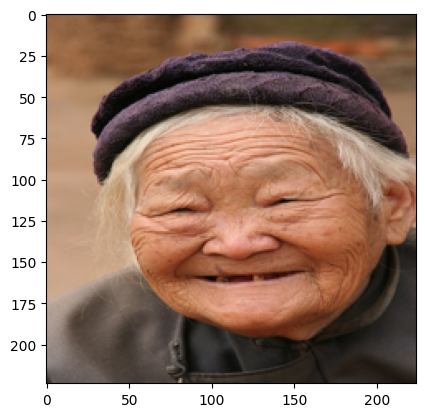

In [48]:
plt.imshow(img_resized)

In [49]:
prediction=model.predict(img_batch,verbose=0)[0][0]

In [50]:
class_names = ["Female", "Male"]
pred_label = 1 if prediction >= 0.5 else 0
confidence= prediction if pred_label == 1 else 1-prediction

In [51]:
print(f"Prediction: {class_names[pred_label]}")
print(f"Confidence: {confidence:.2%}")

Prediction: Female
Confidence: 75.62%
